## Author: Gabriel Vance
## Class: DSC630 - Predictive Analytics
## Professor: Professor Andrew Hua
## Date: September 23, 2025

# Purpose: This notebook utilizes various NLP techniques to train a model to classify news articles as either real or fake. The notebook includes data preprocessing, feature extraction, model training, and evaluation.

### Imports

In [2]:
# Standard library
import re
from collections import Counter

# Data manipulation and analysis
import numpy as np
import pandas as pd

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Statistics
from scipy.stats import skew, kurtosis

# Text processing / NLP
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Deep learning
import tensorflow as tf
from tensorflow.keras.optimizers import Adam

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from transformers import DistilBertTokenizerFast, TFDistilBertForSequenceClassification
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import numpy as np


# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

# Ensure that all code cells are fully visible without scrolling
from IPython.core.display import display, HTML

display(HTML('''
<style>
div.CodeMirror pre {
    white-space: pre !important;
}
</style>
'''))


/Users/gvance67/Library/Python/3.11/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Task 1: Understand data shape

### Read data in

In [3]:
politics_real_df = pd.read_csv('github_set1/politifact_real.csv')
politics_fake_df = pd.read_csv('github_set1/politifact_fake.csv')


### Examine the shape of data

In [4]:
politics_real_df.head()
# the shape is the same for fake and real

,id,news_url,title,tweet_ids
0,politifact14984,http://www.nfib-sbet.org/,National Federation of Independent Business,967132259869487105\t967164368768196609\t967215...
1,politifact12944,http://www.cq.com/doc/newsmakertranscripts-494...,comments in Fayetteville NC,942953459\t8980098198\t16253717352\t1668513250...
2,politifact333,https://web.archive.org/web/20080204072132/htt...,"Romney makes pitch, hoping to close deal : Ele...",NaN
3,politifact4358,https://web.archive.org/web/20110811143753/htt...,Democratic Leaders Say House Democrats Are Uni...,NaN
4,politifact779,https://web.archive.org/web/20070820164107/htt...,"Budget of the United States Government, FY 2008",89804710374154240\t91270460595109888\t96039619...


Conclusion:

# id - unique identifier for each article
# news_url - news soiurce URL
# title - title of the article
# text - text of the article
# tweet_ids  - tweet IDs associated with the article. to find the tweet, append the id to https://twitter.com/i/web/status/{{tweet_id}} i.e. https://twitter.com/i/web/status/284329075902926848

### Task 1: Create number of tweets column to understand engagement

In [5]:
politics_real_df['number_of_tweets'] = politics_real_df['tweet_ids'].apply(lambda x: 0 if pd.isna(x) else len(str(x).split('\t')))
politics_fake_df['number_of_tweets'] = politics_fake_df['tweet_ids'].apply(lambda x: 0 if pd.isna(x) else len(str(x).split('\t')))

In [6]:
print(f"Length of politics_real_df: {len(politics_real_df)}")
print(f"Length of politics_fake_df: {len(politics_fake_df)}")

Length of politics_real_df: 624
Length of politics_fake_df: 432


In [7]:
# Inspect shape with new column
politics_real_df

,id,news_url,title,tweet_ids,number_of_tweets
0,politifact14984,http://www.nfib-sbet.org/,National Federation of Independent Business,967132259869487105\t967164368768196609\t967215...,1174
1,politifact12944,http://www.cq.com/doc/newsmakertranscripts-494...,comments in Fayetteville NC,942953459\t8980098198\t16253717352\t1668513250...,51
2,politifact333,https://web.archive.org/web/20080204072132/htt...,"Romney makes pitch, hoping to close deal : Ele...",NaN,0
3,politifact4358,https://web.archive.org/web/20110811143753/htt...,Democratic Leaders Say House Democrats Are Uni...,NaN,0
4,politifact779,https://web.archive.org/web/20070820164107/htt...,"Budget of the United States Government, FY 2008",89804710374154240\t91270460595109888\t96039619...,8
...,...,...,...,...,...
619,politifact14731,https://www.flake.senate.gov/public/index.cfm/...,Flake: “Religious tests should have no place i...,NaN,0
620,politifact329,https://web.archive.org/web/20080131000131/htt...,Change We Can Believe In,634287923135909888\t946743411100536832\t946816...,182
621,politifact1576,http://www.youtube.com/watch?v=4O8CxZ1OD58,deputy director of national health statistics ...,NaN,0
622,politifact4720,http://www.youtube.com/watch?v=EhyMplwY6HY,Romneys ProLife Conversion Myth or Reality Jun...,188871706637647874,1


Show the mean number of tweets

In [8]:
# Calculate mean number of tweet_ids for fake and real dataframes
mean_fake_tweet_ids = politics_fake_df['number_of_tweets'].mean()
mean_real_tweet_ids = politics_real_df['number_of_tweets'].mean()

print(f"Mean # of tweet_ids (fake): {mean_fake_tweet_ids:.2f}")
print(f"Mean # of tweet_ids (real): {mean_real_tweet_ids:.2f}")

Mean # of tweet_ids (fake): 382.76
Mean # of tweet_ids (real): 670.13


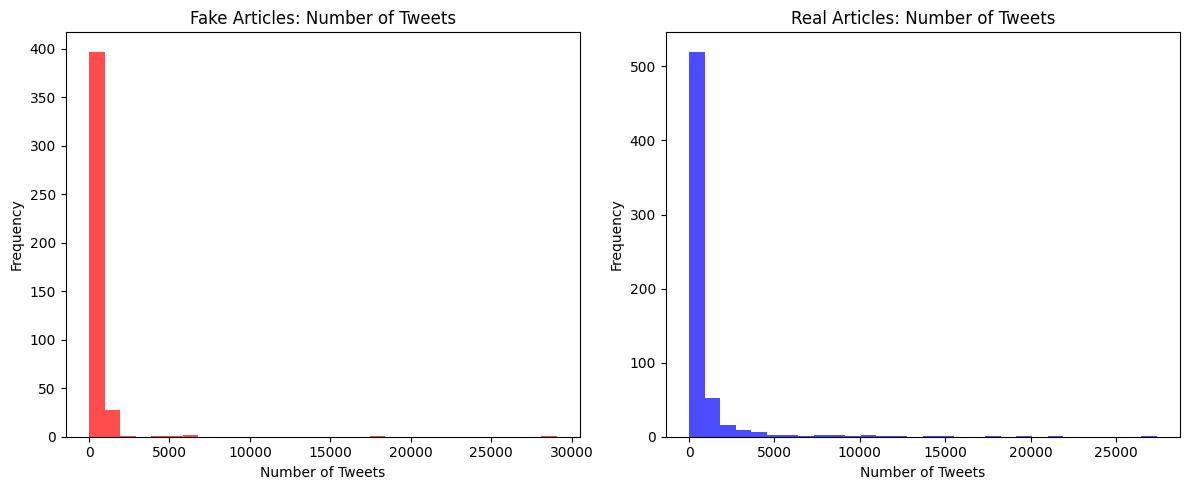

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(politics_fake_df['number_of_tweets'], bins=30, color='red', alpha=0.7)
plt.title('Fake Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
plt.hist(politics_real_df['number_of_tweets'], bins=30, color='blue', alpha=0.7)
plt.title('Real Articles: Number of Tweets')
plt.xlabel('Number of Tweets')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [10]:
num_fake_zeros = (politics_fake_df['number_of_tweets'] == 0).sum()
num_real_zeros = (politics_real_df['number_of_tweets'] == 0).sum()

percent_fake_zeros = num_fake_zeros / len(politics_fake_df) * 100
percent_real_zeros = num_real_zeros / len(politics_real_df) * 100

print(f"Number of fake articles with 0 tweets: {num_fake_zeros} ({percent_fake_zeros:.2f}%)")
print(f"Number of real articles with 0 tweets: {num_real_zeros} ({percent_real_zeros:.2f}%)")

Number of fake articles with 0 tweets: 40 (9.26%)
Number of real articles with 0 tweets: 215 (34.46%)


In [11]:

# Skewness and kurtosis for number_of_tweets
fake_skew = skew(politics_fake_df['number_of_tweets'])
real_skew = skew(politics_real_df['number_of_tweets'])
fake_kurt = kurtosis(politics_fake_df['number_of_tweets'])
real_kurt = kurtosis(politics_real_df['number_of_tweets'])

print(f"Fake Articles - Skewness: {fake_skew:.2f}, Kurtosis: {fake_kurt:.2f}")
print(f"Real Articles - Skewness: {real_skew:.2f}, Kurtosis: {real_kurt:.2f}")

Fake Articles - Skewness: 13.16, Kurtosis: 196.74
Real Articles - Skewness: 6.55, Kurtosis: 52.10


In [12]:
print("Fake Articles - Number of Tweets Distribution:")
print(politics_fake_df['number_of_tweets'].describe())
print("\nReal Articles - Number of Tweets Distribution:")
print(politics_real_df['number_of_tweets'].describe())

Fake Articles - Number of Tweets Distribution:
count      432.000000
mean       382.759259
std       1728.420580
min          0.000000
25%         12.000000
50%         79.000000
75%        291.500000
max      29060.000000
Name: number_of_tweets, dtype: float64

Real Articles - Number of Tweets Distribution:
count      624.000000
mean       670.134615
std       2357.062320
min          0.000000
25%          0.000000
50%          8.000000
75%        167.000000
max      27377.000000
Name: number_of_tweets, dtype: float64


In [13]:
# Titles with number_of_tweets == 0 (first 5)
print("Titles with 0 tweets (first 5):")
for title in politics_real_df[politics_real_df['number_of_tweets'] == 0]['title'].head(5):
    print(title)

# Titles with highest number_of_tweets (top 5)
print("\nTitles with highest tweet counts (top 5):")
for title in politics_real_df.sort_values('number_of_tweets', ascending=False)['title'].head(5):
    print(title)

Titles with 0 tweets (first 5):
Romney makes pitch, hoping to close deal : Elections : The Rocky Mountain News
Democratic Leaders Say House Democrats Are United Against GOP Default Act
子供たちのコト。私のコト。
Covering Young Adults Under the Affordable Care Act: The Importance of Outreach and Medicaid Expansion
Summary of the Affordable Care Act

Titles with highest tweet counts (top 5):
One in Four – Congressman Joe Pitts – Medium
Rep. Michael McCaul (R-TX) Appears on Face the Nation
Outlook, Office, Skype, Bing, Breaking News, and Latest Videos
interview on Fox News
"One Hundred Percent" by Club for Growth Action


### The tweet counts are heavily right-skewed. Log typically helps with this, so we'll normalize with log1p (log(1+x)) which handles zeros.

In [14]:
politics_real_df["number_of_tweets_log"] = np.log1p(politics_real_df["number_of_tweets"])  
politics_fake_df["number_of_tweets_log"] = np.log1p(politics_fake_df["number_of_tweets"])  

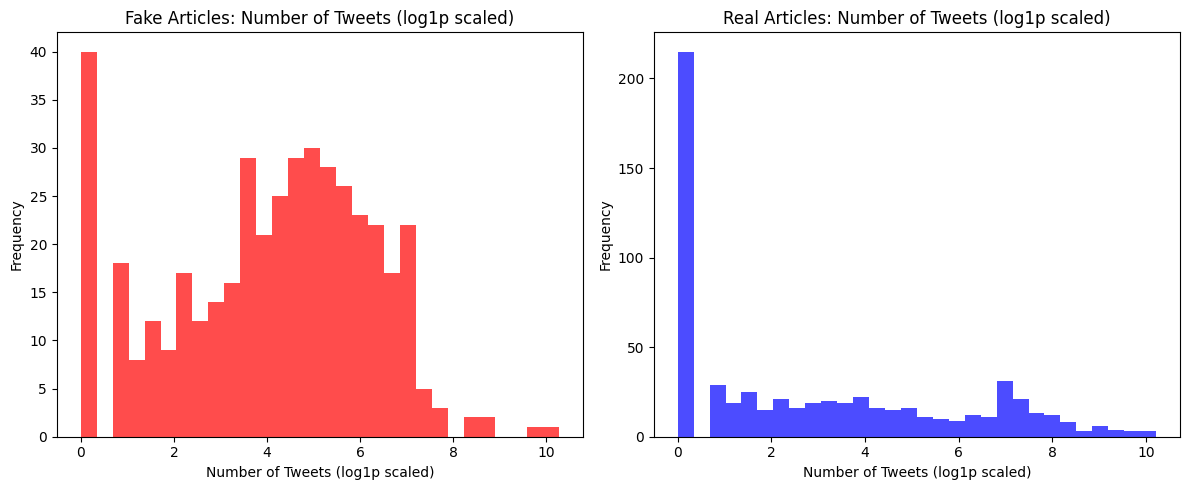

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(politics_fake_df['number_of_tweets_log'], bins=30, color='red', alpha=0.7)
plt.title('Fake Articles: Number of Tweets (log1p scaled)')
plt.xlabel('Number of Tweets (log1p scaled)')
plt.ylabel('Frequency')



plt.subplot(1, 2, 2)
plt.hist(politics_real_df['number_of_tweets_log'], bins=30, color='blue', alpha=0.7)
plt.title('Real Articles: Number of Tweets (log1p scaled)')
plt.xlabel('Number of Tweets (log1p scaled)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [16]:

# Calculate mean number of tweet_ids for fake and real dataframes
mean_fake_tweet_ids = politics_fake_df['number_of_tweets_log'].mean()
mean_real_tweet_ids = politics_real_df['number_of_tweets_log'].mean()

print(f"Mean # of tweet_ids (fake): {mean_fake_tweet_ids:.2f}")
print(f"Mean # of tweet_ids (real): {mean_real_tweet_ids:.2f}")

Mean # of tweet_ids (fake): 4.04
Mean # of tweet_ids (real): 2.90


In [17]:

# Skewness and kurtosis for number_of_tweets
fake_skew_log = skew(politics_fake_df['number_of_tweets_log'])
real_skew_log = skew(politics_real_df['number_of_tweets_log'])
fake_kurt_log = kurtosis(politics_fake_df['number_of_tweets_log'])
real_kurt_log = kurtosis(politics_real_df['number_of_tweets_log'])

print(f"Fake Articles - Skewness: {fake_skew_log:.2f}, Kurtosis: {fake_kurt_log:.2f}")
print(f"Real Articles - Skewness: {real_skew_log:.2f}, Kurtosis: {real_kurt_log:.2f}")

Fake Articles - Skewness: -0.30, Kurtosis: -0.62
Real Articles - Skewness: 0.61, Kurtosis: -0.95


In [18]:

# Calculate TextBlob polarity sentiment for each title
politics_real_df['blob_sentiment'] = politics_real_df['title'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)
politics_fake_df['blob_sentiment'] = politics_fake_df['title'].apply(lambda x: TextBlob(str(x)).sentiment.polarity)

# Show summary statistics
print("Real News TextBlob Sentiment:")
print(politics_real_df['blob_sentiment'].describe())
print("\nFake News TextBlob Sentiment:")
print(politics_fake_df['blob_sentiment'].describe())


Real News TextBlob Sentiment:
count    624.000000
mean       0.038518
std        0.161547
min       -0.700000
25%        0.000000
50%        0.000000
75%        0.000000
max        1.000000
Name: blob_sentiment, dtype: float64

Fake News TextBlob Sentiment:
count    432.000000
mean       0.005980
std        0.222265
min       -1.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        0.900000
Name: blob_sentiment, dtype: float64


In [19]:
# Top 5 positive sentiment headlines (real news)
print("Top 5 positive sentiment headlines (Real News):")
print(politics_real_df.sort_values('blob_sentiment', ascending=False)[['title', 'blob_sentiment']].head(5))

# Bottom 5 negative sentiment headlines (real news)
print("\nBottom 5 negative sentiment headlines (Real News):")
print(politics_real_df.sort_values('blob_sentiment')[['title', 'blob_sentiment']].head(5))

# Top 5 positive sentiment headlines (fake news)
print("\nTop 5 positive sentiment headlines (Fake News):")
print(politics_fake_df.sort_values('blob_sentiment', ascending=False)[['title', 'blob_sentiment']].head(5))

# Bottom 5 negative sentiment headlines (fake news)
print("\nBottom 5 negative sentiment headlines (Fake News):")
print(politics_fake_df.sort_values('blob_sentiment')[['title', 'blob_sentiment']].head(5))

Top 5 positive sentiment headlines (Real News):
                                                 title  blob_sentiment
507                          Americas 5 Best Governors             1.0
504            Kerry-McCain: Welcome To Massachusetts!             1.0
590   Remarks of Senator Obama: The War We Need to Win             0.8
431   Israel should welcome Rouhani's election victory             0.8
101  About Bright Horizons Child Care & Family Solu...             0.7

Bottom 5 negative sentiment headlines (Real News):
                                                 title  blob_sentiment
393  Carolyn B. Maloney on Twitter: "Women's health...            -0.7
532  Laura Ingraham wrongly says claim that 90% sup...            -0.5
77         At Trump hotel site, immigrant workers wary            -0.5
602  Sen. Sanders warns of ‘frightening trend’ towa...            -0.5
16             Impeachment Talk Becomes a Cynical Game            -0.5

Top 5 positive sentiment headlines (Fake News):

In [20]:
# Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# Apply sentiment analysis to each title
politics_real_df["vader_sentiment"] = politics_real_df["title"].apply(lambda x: analyzer.polarity_scores(str(x)))
politics_fake_df["vader_sentiment"] = politics_fake_df["title"].apply(lambda x: analyzer.polarity_scores(str(x)))

# Expand the sentiment dictionary into separate columns
sentiment_df_real = politics_real_df["vader_sentiment"].apply(pd.Series)
sentiment_df_fake = politics_fake_df["vader_sentiment"].apply(pd.Series)

# Merge back into your DataFrame
politics_real_df = pd.concat([politics_real_df, sentiment_df_real], axis=1)
politics_fake_df = pd.concat([politics_fake_df, sentiment_df_fake], axis=1)

# Calculate mean sentiment values for real and fake
real_means = politics_real_df[["neg", "neu", "pos", "compound"]].mean()
fake_means = politics_fake_df[["neg", "neu", "pos", "compound"]].mean()

print("Average sentiment (REAL):\n", real_means, "\n")
print("Average sentiment (FAKE):\n", fake_means, "\n")


Average sentiment (REAL):
 neg         0.051676
neu         0.881439
pos         0.066880
compound    0.015800
dtype: float64 

Average sentiment (FAKE):
 neg         0.144245
neu         0.796495
pos         0.059275
compound   -0.162425
dtype: float64 



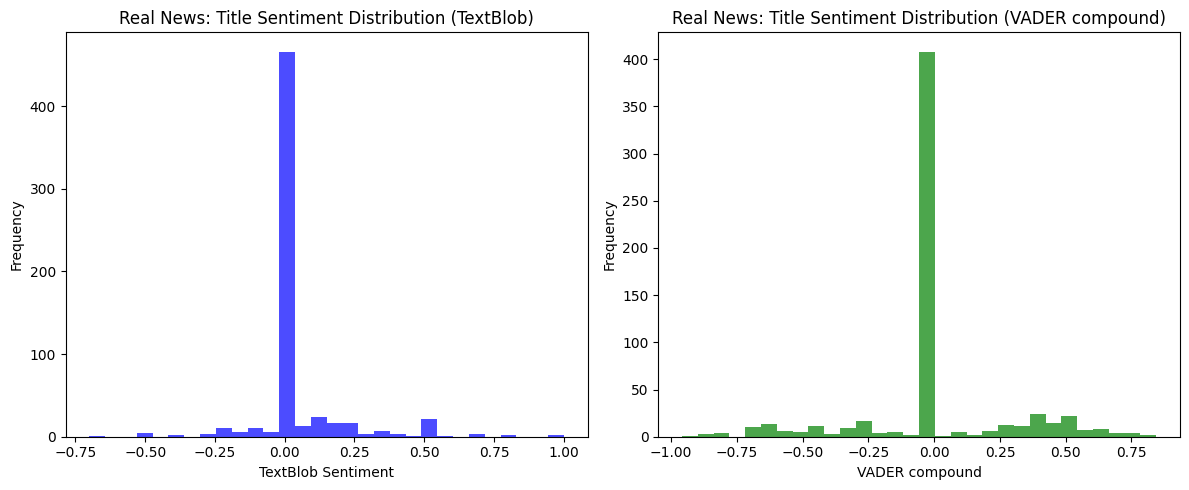

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(politics_real_df['blob_sentiment'], bins=30, color='blue', alpha=0.7)
plt.title('Real News: Title Sentiment Distribution (TextBlob)')
plt.xlabel('TextBlob Sentiment')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
# plot the VADER compound score (vader_sentiment column contains dicts which are unhashable)
plt.hist(politics_real_df['compound'], bins=30, color='green', alpha=0.7)
plt.title('Real News: Title Sentiment Distribution (VADER compound)')
plt.xlabel('VADER compound')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# Function to extract keywords
def get_keywords(text_series, stopwords=None, top_n=20):
    # Lowercase, remove punctuation, split, and filter stopwords
    words = []
    for text in text_series.dropna():
        tokens = re.findall(r'\b\w+\b', text.lower())
        if stopwords:
            tokens = [w for w in tokens if w not in stopwords]
        words.extend(tokens)
    return Counter(words).most_common(top_n)

# Use sklearn's built-in English stopwords

fake_keywords = get_keywords(politics_fake_df['title'], stopwords=ENGLISH_STOP_WORDS)
real_keywords = get_keywords(politics_real_df['title'], stopwords=ENGLISH_STOP_WORDS)

print("Most common keywords in fake news titles:")
print(fake_keywords)
print("\nMost common keywords in real news titles:")
print(real_keywords)

Most common keywords in fake news titles:
[('trump', 106), ('breaking', 63), ('s', 58), ('obama', 51), ('just', 38), ('president', 22), ('clinton', 21), ('donald', 21), ('news', 20), ('says', 16), ('t', 16), ('new', 15), ('white', 15), ('hillary', 13), ('arrested', 13), ('million', 12), ('dead', 11), ('3', 11), ('killed', 11), ('school', 10)]

Most common keywords in real news titles:
[('s', 101), ('obama', 60), ('transcript', 47), ('president', 41), ('news', 33), ('u', 31), ('debate', 30), ('remarks', 29), ('senate', 28), ('mccain', 26), ('says', 24), ('trump', 23), ('clinton', 22), ('health', 21), ('ad', 19), ('week', 19), ('care', 18), ('presidential', 18), ('congress', 18), ('barack', 18)]


### Viral tweets heavily skewed the right data, so much so that before normalization the mean was almost twice that of fake news. This is also confusing because fake news only had 0 tweets 9% of the time whereas ~1/3 (34%) of real news had 0 tweets. 

### We can conclude that fake news is more consistently shared on Twitter, whereas real news is either not shared at all or goes viral. Fake news appears to be more consistent whereas real news is sporadic. When comparing headlines of real viral news vs non-viral news, the viral news doesn't appear to be more sensationalized. For example, "Summary of the Affordable Care Act" had 0 tweets whereas the most tweeted article was "One in Four – Congressman Joe Pitts – Medium", which is a personal opinion piece.

In [ ]:
# # Combine real and fake dataframes
# politics_real_df['real'] = 1
# politics_fake_df['real'] = 0
# combined_df = pd.concat([politics_real_df, politics_fake_df], ignore_index=True)

# # Drop rows where title is NaN
# combined_df = combined_df.dropna(subset=['title'])

# # Prepare features and target
# X = combined_df['title']
# y = combined_df['real']

# # Split data
# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42, stratify=y
# )

# # Define models
# models = {
#     "TF-IDF + Logistic Regression": Pipeline([
#         ('tfidf', TfidfVectorizer(stop_words='english')),
#         ('lr', LogisticRegression(max_iter=1000))
#     ]),
    
#     "TF-IDF + Linear SVM": Pipeline([
#         ('tfidf', TfidfVectorizer(stop_words='english')),
#         ('svm', LinearSVC())
#     ]),
    
#     "CountVectorizer + Naive Bayes": Pipeline([
#         ('cv', CountVectorizer(stop_words='english')),
#         ('nb', MultinomialNB())
#     ])
# }
# saved_models = {}
# # Loop through classical models
# for name, model in models.items():
#     print(f"\n===== {name} =====")
#     model.fit(X_train, y_train)
#     y_pred = model.predict(X_test)
#     print(classification_report(y_test, y_pred))
#     saved_models[name] = model

# # ---- DistilBERT model ----
# print("\n===== DistilBERT Transformer =====")

# tokenizer = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

# X_train_tok = tokenizer(list(X_train), truncation=True, padding=True, return_tensors='tf')
# X_test_tok = tokenizer(list(X_test), truncation=True, padding=True, return_tensors='tf')

# bert_model = TFDistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=2)

# bert_model.compile(
#     optimizer=Adam(learning_rate=5e-5),
#     loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
#     metrics=['accuracy']
# )

# bert_model.fit(
#     X_train_tok.data,
#     np.array(y_train),
#     validation_split=0.1,
#     epochs=1,  # change to more epochs for better results
#     batch_size=8,
#     verbose=1
# )

# y_pred_bert = np.argmax(bert_model.predict(X_test_tok.data).logits, axis=1)
# print(classification_report(y_test, y_pred_bert))
